<a href="https://colab.research.google.com/github/saketh-varma06/DL_ASSIGNMENTS/blob/main/DL_ASS2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [ ]:
df=pd.read_csv("/content/insurance.csv")
x=pd.get_dummies(df.drop(["charges"],axis=1),drop_first=True)
y=df[["charges"]].values
x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)
scaler_x=StandardScaler()
scaler_y=StandardScaler()
x_train=scaler_x.fit_transform(x_train)
y_train=scaler_y.fit_transform(y_train)
x_test=scaler_x.transform(x_test)
y_test=scaler_y.transform(y_test)


In [ ]:
import torch.nn as nn
class salarypredictor(nn.Module):
    def __init__(self, input_size):
        super(salarypredictor, self).__init__()
        self.linear=nn.Linear(input_size, 1)
    def forward(self, x):
        return self.linear(x)
input_size=x_train.shape[1]
model=salarypredictor(input_size)

In [ ]:
model=salarypredictor()
criterion=nn.MSELoss()
optimizer=torch.optim.SGD(model.parameters(),lr=0.01)

In [ ]:
x_train = torch.FloatTensor(x_train)
x_test = torch.FloatTensor(x_test)
y_train = torch.FloatTensor(y_train)
y_test = torch.FloatTensor(y_test)
print(type(x_train))
print(type(y_train))

<class 'torch.Tensor'>
<class 'torch.Tensor'>


In [ ]:
epochs=500
losses=[]
for epoch in range(epochs):
    outputs=model(x_train)
    loss=criterion(outputs, y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if (epoch + 1) % 50==0:
        print(f"Epoch {epoch+1}, Loss={loss.item():.4f}")

Epoch 50, Loss=1.1029
Epoch 100, Loss=1.1029
Epoch 150, Loss=1.1029
Epoch 200, Loss=1.1029
Epoch 250, Loss=1.1029
Epoch 300, Loss=1.1029
Epoch 350, Loss=1.1029
Epoch 400, Loss=1.1029
Epoch 450, Loss=1.1029
Epoch 500, Loss=1.1029


In [ ]:
model.eval()
with torch.no_grad():
    predictions=model(x_test)
predictions=scaler_y.inverse_transform(predictions.numpy())
actual=scaler_y.inverse_transform(y_test.numpy())

In [ ]:
mae = mean_absolute_error(actual, predictions)
mse = mean_squared_error(actual, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(actual, predictions)
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE : 10034.15625
MSE : 172877696.0
RMSE: 13148.296315492742
R2 Score: -0.11355304718017578


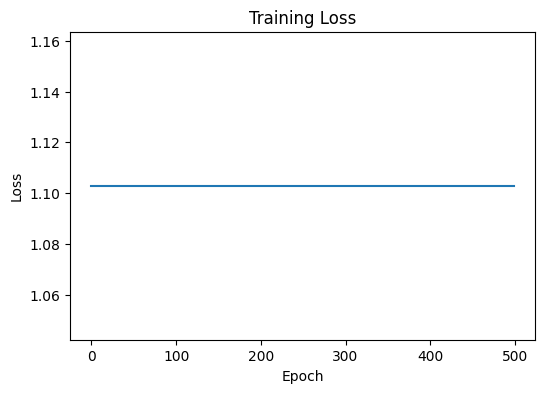

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(losses)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

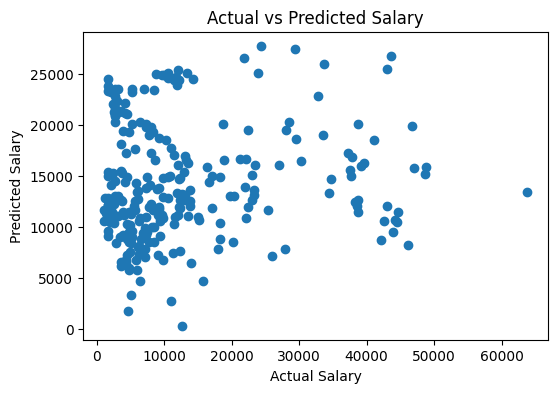

In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(actual, predictions)
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")
plt.show()